In [1]:

import os

print("Current directory:", os.getcwd())
print("\nCSV files found in Colab:")

for root, dirs, files in os.walk("/content"):
    dirs[:] = [d for d in dirs if d not in ["drive/.Trash-1000"]]
    for file in files:
        if file.lower().endswith(".csv"):
            path = os.path.join(root, file)
            print(f"{file}  |  {os.path.getsize(path) / (1024**2):.2f} MB")


Current directory: /content

CSV files found in Colab:
Friday-WorkingHours-Morning.pcap_ISCX.csv  |  55.62 MB
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv  |  49.61 MB
Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv  |  73.55 MB
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv  |  73.34 MB
Tuesday-WorkingHours.pcap_ISCX.csv  |  128.82 MB
Monday-WorkingHours.pcap_ISCX.csv  |  168.73 MB
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv  |  79.25 MB
CICDarknet.CSV  |  69.93 MB
Wednesday-workingHours.pcap_ISCX.csv  |  214.74 MB
mnist_test.csv  |  17.44 MB
mnist_train_small.csv  |  34.83 MB
california_housing_train.csv  |  1.63 MB
california_housing_test.csv  |  0.29 MB


In [2]:

import pandas as pd
import os
import glob

# Locate the dataset files
files = glob.glob("/content/*.csv")

# Select the research datasets, excluding unrelated sample datasets
dataset_files = [
    f for f in files
    if os.path.basename(f).startswith((
        "CICDarknet",
        "Monday-WorkingHours",
        "Tuesday-WorkingHours",
        "Wednesday-workingHours",
        "Thursday-WorkingHours",
        "Friday-WorkingHours"
    ))
]

for file in dataset_files:
    print("\n" + "=" * 70)
    print("FILE:", os.path.basename(file))

    try:
        df = pd.read_csv(file, nrows=5, low_memory=False)
        print("Number of columns:", len(df.columns))
        print("Column names:")
        print(df.columns.tolist())

        # Inspect the last column, which often contains the label
        print("\nLast column:", repr(df.columns[-1]))
        print("Sample values:")
        print(df.iloc[:, -1].head().tolist())

    except Exception as e:
        print("Error:", e)



FILE: Friday-WorkingHours-Morning.pcap_ISCX.csv
Number of columns: 79
Column names:
[' Destination Port', ' Flow Duration', ' Total Fwd Packets', ' Total Backward Packets', 'Total Length of Fwd Packets', ' Total Length of Bwd Packets', ' Fwd Packet Length Max', ' Fwd Packet Length Min', ' Fwd Packet Length Mean', ' Fwd Packet Length Std', 'Bwd Packet Length Max', ' Bwd Packet Length Min', ' Bwd Packet Length Mean', ' Bwd Packet Length Std', 'Flow Bytes/s', ' Flow Packets/s', ' Flow IAT Mean', ' Flow IAT Std', ' Flow IAT Max', ' Flow IAT Min', 'Fwd IAT Total', ' Fwd IAT Mean', ' Fwd IAT Std', ' Fwd IAT Max', ' Fwd IAT Min', 'Bwd IAT Total', ' Bwd IAT Mean', ' Bwd IAT Std', ' Bwd IAT Max', ' Bwd IAT Min', 'Fwd PSH Flags', ' Bwd PSH Flags', ' Fwd URG Flags', ' Bwd URG Flags', ' Fwd Header Length', ' Bwd Header Length', 'Fwd Packets/s', ' Bwd Packets/s', ' Min Packet Length', ' Max Packet Length', ' Packet Length Mean', ' Packet Length Std', ' Packet Length Variance', 'FIN Flag Count', ' 

In [3]:

import pandas as pd
import glob
import os
from collections import Counter

files = glob.glob("/content/*.csv")

dataset_files = [
    f for f in files
    if os.path.basename(f).startswith((
        "CICDarknet",
        "Monday-WorkingHours",
        "Tuesday-WorkingHours",
        "Wednesday-workingHours",
        "Thursday-WorkingHours",
        "Friday-WorkingHours"
    ))
]

for file in dataset_files:
    print("\n" + "=" * 60)
    print("Dataset:", os.path.basename(file))

    counts = Counter()
    total_rows = 0
    columns = None

    for chunk in pd.read_csv(file, chunksize=100_000, low_memory=False):
        chunk.columns = chunk.columns.str.strip()
        columns = chunk.columns.tolist()

        label_col = next(
            (c for c in columns if c.lower() == "label"),
            None
        )

        if label_col is None:
            print("ERROR: Label column not found")
            break

        labels = chunk[label_col].astype("string").str.strip()
        counts.update(labels.value_counts(dropna=False).to_dict())
        total_rows += len(chunk)

    print("Total rows:", total_rows)
    print("Number of columns:", len(columns) if columns else 0)
    print("Class distribution:")

    for label, count in counts.most_common():
        print(f"{label}: {count:,}")



Dataset: Friday-WorkingHours-Morning.pcap_ISCX.csv
Total rows: 191033
Number of columns: 79
Class distribution:
BENIGN: 189,067
Bot: 1,966

Dataset: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Total rows: 170366
Number of columns: 79
Class distribution:
BENIGN: 168,186
Web Attack � Brute Force: 1,507
Web Attack � XSS: 652
Web Attack � Sql Injection: 21

Dataset: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Total rows: 225745
Number of columns: 79
Class distribution:
DDoS: 128,027
BENIGN: 97,718

Dataset: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Total rows: 286467
Number of columns: 79
Class distribution:
PortScan: 158,930
BENIGN: 127,537

Dataset: Tuesday-WorkingHours.pcap_ISCX.csv
Total rows: 445909
Number of columns: 79
Class distribution:
BENIGN: 432,074
FTP-Patator: 7,938
SSH-Patator: 5,897

Dataset: Monday-WorkingHours.pcap_ISCX.csv
Total rows: 529918
Number of columns: 79
Class distribution:
BENIGN: 529,918

Dataset: Thursday-WorkingHours-Afternoon-Inf

In [4]:

import pandas as pd
import numpy as np

# Inspect CICDarknet
darknet_path = "/content/CICDarknet.CSV"

darknet = pd.read_csv(darknet_path, nrows=10, low_memory=False)

print("CICDarknet columns:", len(darknet.columns))
print("\nColumn names:")
print(darknet.columns.tolist())

print("\nFirst 5 rows:")
display(darknet.head())

print("\nData types:")
print(darknet.dtypes.value_counts())

# Inspect a CICIDS2017 file
cic_path = "/content/Monday-WorkingHours.pcap_ISCX.csv"

cic = pd.read_csv(cic_path, nrows=1000, low_memory=False)
cic.columns = cic.columns.str.strip()

print("\nCICIDS2017 columns:", len(cic.columns))
print("Label column:", [c for c in cic.columns if c.lower() == "label"])

print("\nNumeric feature count:")
print(len(cic.select_dtypes(include=np.number).columns))

print("\nMissing values in the sample:")
print(cic.isna().sum().sum())

print("\nInfinite values in numeric sample:")
numeric = cic.select_dtypes(include=np.number)
print(np.isinf(numeric).sum().sum())


CICDarknet columns: 85

Column names:
['Flow ID', 'Src IP', 'Src Port', 'Dst IP', 'Dst Port', 'Protocol', 'Timestamp', 'Flow Duration', 'Total Fwd Packet', 'Total Bwd packets', 'Total Length of Fwd Packet', 'Total Length of Bwd Packet', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Packet Length Min', 'Packet Length Max', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count

,Flow ID,Src IP,Src Port,Dst IP,Dst Port,Protocol,Timestamp,Flow Duration,Total Fwd Packet,Total Bwd packets,...,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label,Label.1
0,10.152.152.11-216.58.220.99-57158-443-6,10.152.152.11,57158,216.58.220.99,443,6,24/07/2015 04:09:48 PM,229,1,1,...,0,0,0,0,0.000000e+00,0.000000e+00,0,0,Non-Tor,AUDIO-STREAMING
1,10.152.152.11-216.58.220.99-57159-443-6,10.152.152.11,57159,216.58.220.99,443,6,24/07/2015 04:09:48 PM,407,1,1,...,0,0,0,0,0.000000e+00,0.000000e+00,0,0,Non-Tor,AUDIO-STREAMING
2,10.152.152.11-216.58.220.99-57160-443-6,10.152.152.11,57160,216.58.220.99,443,6,24/07/2015 04:09:48 PM,431,1,1,...,0,0,0,0,0.000000e+00,0.000000e+00,0,0,Non-Tor,AUDIO-STREAMING
3,10.152.152.11-74.125.136.120-49134-443-6,10.152.152.11,49134,74.125.136.120,443,6,24/07/2015 04:09:48 PM,359,1,1,...,0,0,0,0,0.000000e+00,0.000000e+00,0,0,Non-Tor,AUDIO-STREAMING
4,10.152.152.11-173.194.65.127-34697-19305-6,10.152.152.11,34697,173.194.65.127,19305,6,24/07/2015 04:09:45 PM,10778451,591,400,...,0,0,0,0,1.437765e+15,3.117718e+06,1437764995910109,1437764985151822,Non-Tor,AUDIO-STREAMING



Data types:
int64      57
float64    22
object      6
Name: count, dtype: int64

CICIDS2017 columns: 79
Label column: ['Label']

Numeric feature count:
78

Missing values in the sample:
0

Infinite values in numeric sample:
20


In [5]:

import pandas as pd

path = "/content/CICDarknet.CSV"

# Inspect all column names
df_sample = pd.read_csv(path, nrows=1000, low_memory=False)

print("ALL DARKNET COLUMNS:")
for i, col in enumerate(df_sample.columns):
    print(i, repr(col))

print("\nPOSSIBLE LABEL COLUMNS:")
for col in df_sample.columns:
    if any(word in col.lower() for word in ["label", "class", "category", "attack"]):
        print(repr(col), "->", df_sample[col].value_counts().head(10).to_dict())

print("\nMISSING VALUES IN SAMPLE:")
print(df_sample.isna().sum().sort_values(ascending=False).head(10))

print("\nOBJECT-TYPE COLUMNS:")
print(df_sample.select_dtypes(include="object").columns.tolist())


ALL DARKNET COLUMNS:
0 'Flow ID'
1 'Src IP'
2 'Src Port'
3 'Dst IP'
4 'Dst Port'
5 'Protocol'
6 'Timestamp'
7 'Flow Duration'
8 'Total Fwd Packet'
9 'Total Bwd packets'
10 'Total Length of Fwd Packet'
11 'Total Length of Bwd Packet'
12 'Fwd Packet Length Max'
13 'Fwd Packet Length Min'
14 'Fwd Packet Length Mean'
15 'Fwd Packet Length Std'
16 'Bwd Packet Length Max'
17 'Bwd Packet Length Min'
18 'Bwd Packet Length Mean'
19 'Bwd Packet Length Std'
20 'Flow Bytes/s'
21 'Flow Packets/s'
22 'Flow IAT Mean'
23 'Flow IAT Std'
24 'Flow IAT Max'
25 'Flow IAT Min'
26 'Fwd IAT Total'
27 'Fwd IAT Mean'
28 'Fwd IAT Std'
29 'Fwd IAT Max'
30 'Fwd IAT Min'
31 'Bwd IAT Total'
32 'Bwd IAT Mean'
33 'Bwd IAT Std'
34 'Bwd IAT Max'
35 'Bwd IAT Min'
36 'Fwd PSH Flags'
37 'Bwd PSH Flags'
38 'Fwd URG Flags'
39 'Bwd URG Flags'
40 'Fwd Header Length'
41 'Bwd Header Length'
42 'Fwd Packets/s'
43 'Bwd Packets/s'
44 'Packet Length Min'
45 'Packet Length Max'
46 'Packet Length Mean'
47 'Packet Length Std'
48 'Packe

In [6]:

import pandas as pd

path = "/content/CICDarknet.CSV"

counts = {"Label": {}, "Label.1": {}}

for chunk in pd.read_csv(path, chunksize=100_000, low_memory=False):
    chunk.columns = chunk.columns.str.strip()

    for col in counts:
        if col in chunk.columns:
            values = chunk[col].astype("string").str.strip()
            values = values.fillna("<MISSING>")
            current = values.value_counts().to_dict()

            for label, n in current.items():
                counts[col][label] = counts[col].get(label, 0) + n

for col, distribution in counts.items():
    print("\n" + "=" * 50)
    print("TARGET:", col)
    print("Number of classes:", len(distribution))

    for label, n in sorted(
        distribution.items(), key=lambda x: x[1], reverse=True
    ):
        print(f"{label}: {n:,}")



TARGET: Label
Number of classes: 4
Non-Tor: 110,442
NonVPN: 23,863
VPN: 22,919
Tor: 1,392

TARGET: Label.1
Number of classes: 11
P2P: 48,520
Browsing: 46,457
Audio-Streaming: 19,830
Chat: 11,629
File-Transfer: 11,098
Video-Streaming: 9,486
Email: 6,145
VOIP: 3,566
AUDIO-STREAMING: 1,520
Video-streaming: 281
File-transfer: 84


In [7]:

from google.colab import drive
drive.mount("/content/drive")

import os

OUTPUT_DIR = "/content/drive/MyDrive/Intrusion_Detection_Paper_Results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Results folder:", OUTPUT_DIR)
print("Folder exists:", os.path.isdir(OUTPUT_DIR))


Mounted at /content/drive
Results folder: /content/drive/MyDrive/Intrusion_Detection_Paper_Results
Folder exists: True


In [8]:

import os
import glob
import pandas as pd
from collections import Counter

OUTPUT_DIR = "/content/drive/MyDrive/Intrusion_Detection_Paper_Results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Find CICIDS2017 weekday files
cic_files = [
    f for f in glob.glob("/content/*.csv")
    if os.path.basename(f).startswith((
        "Monday-WorkingHours",
        "Tuesday-WorkingHours",
        "Wednesday-workingHours",
        "Thursday-WorkingHours",
        "Friday-WorkingHours"
    ))
]

audit_rows = []

# Count CICIDS2017 labels across all available files
for path in sorted(cic_files):
    counts = Counter()
    total = 0

    for chunk in pd.read_csv(path, chunksize=100_000, low_memory=False):
        chunk.columns = chunk.columns.str.strip()
        label_col = next(
            (c for c in chunk.columns if c.lower() == "label"),
            None
        )

        if label_col is None:
            raise ValueError(f"Label column missing: {path}")

        labels = chunk[label_col].astype("string").str.strip()
        counts.update(labels.fillna("<MISSING>").value_counts().to_dict())
        total += len(chunk)

    for label, count in counts.items():
        audit_rows.append({
            "dataset": "CICIDS2017",
            "file": os.path.basename(path),
            "class": label,
            "count": count,
            "file_total": total
        })

# Count the two distinct Darknet targets
darknet_path = "/content/CICDarknet.CSV"
darknet_counts = {"Label": Counter(), "Label.1": Counter()}

for chunk in pd.read_csv(darknet_path, chunksize=100_000, low_memory=False):
    chunk.columns = chunk.columns.str.strip()

    for col in darknet_counts:
        if col not in chunk.columns:
            raise ValueError(f"Missing Darknet target: {col}")

        labels = chunk[col].astype("string").str.strip()
        darknet_counts[col].update(
            labels.fillna("<MISSING>").value_counts().to_dict()
        )

for target, counts in darknet_counts.items():
    for label, count in counts.items():
        audit_rows.append({
            "dataset": "CICDarknet2020",
            "file": os.path.basename(darknet_path),
            "class": f"{target}={label}",
            "count": count,
            "file_total": sum(counts.values())
        })

audit = pd.DataFrame(audit_rows)
audit_path = os.path.join(OUTPUT_DIR, "dataset_class_audit.csv")
audit.to_csv(audit_path, index=False)

print("CICIDS2017 files found:", len(cic_files))
print("Darknet target columns: Label and Label.1")
print("Audit saved to:", audit_path)
display(audit.head(20))


CICIDS2017 files found: 8
Darknet target columns: Label and Label.1
Audit saved to: /content/drive/MyDrive/Intrusion_Detection_Paper_Results/dataset_class_audit.csv


,dataset,file,class,count,file_total
0,CICIDS2017,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,DDoS,128027,225745
1,CICIDS2017,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,BENIGN,97718,225745
2,CICIDS2017,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,BENIGN,127537,286467
3,CICIDS2017,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,PortScan,158930,286467
4,CICIDS2017,Friday-WorkingHours-Morning.pcap_ISCX.csv,BENIGN,189067,191033
5,CICIDS2017,Friday-WorkingHours-Morning.pcap_ISCX.csv,Bot,1966,191033
6,CICIDS2017,Monday-WorkingHours.pcap_ISCX.csv,BENIGN,529918,529918
7,CICIDS2017,Thursday-WorkingHours-Afternoon-Infilteration....,BENIGN,288566,288602
8,CICIDS2017,Thursday-WorkingHours-Afternoon-Infilteration....,Infiltration,36,288602
9,CICIDS2017,Thursday-WorkingHours-Morning-WebAttacks.pcap_...,BENIGN,168186,170366


In [9]:

import pandas as pd
import os

audit_path = (
    "/content/drive/MyDrive/Intrusion_Detection_Paper_Results/"
    "dataset_class_audit.csv"
)

audit = pd.read_csv(audit_path)

summary = (
    audit[audit["dataset"] == "CICIDS2017"]
    [["file", "file_total"]]
    .drop_duplicates()
    .sort_values("file")
)

print("CICIDS2017 source-file summary")
display(summary)

print("\nNumber of source files:", len(summary))
print("Sum of rows across source files:", summary["file_total"].sum())

print("\nAudit file exists:", os.path.exists(audit_path))


CICIDS2017 source-file summary


,file,file_total
0,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,225745
2,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,286467
4,Friday-WorkingHours-Morning.pcap_ISCX.csv,191033
6,Monday-WorkingHours.pcap_ISCX.csv,529918
7,Thursday-WorkingHours-Afternoon-Infilteration....,288602
9,Thursday-WorkingHours-Morning-WebAttacks.pcap_...,170366
13,Tuesday-WorkingHours.pcap_ISCX.csv,445909
16,Wednesday-workingHours.pcap_ISCX.csv,692703



Number of source files: 8
Sum of rows across source files: 2830743

Audit file exists: True


In [10]:

import pandas as pd
import glob
import os
from collections import Counter

files = [
    f for f in glob.glob("/content/*.csv")
    if os.path.basename(f).startswith((
        "Monday-WorkingHours",
        "Tuesday-WorkingHours",
        "Wednesday-workingHours",
        "Thursday-WorkingHours",
        "Friday-WorkingHours"
    ))
]

overall_counts = Counter()
file_summary = []

for path in sorted(files):
    counts = Counter()
    rows = 0

    for chunk in pd.read_csv(path, chunksize=100_000, low_memory=False):
        chunk.columns = chunk.columns.str.strip()
        label_col = next(
            (c for c in chunk.columns if c.lower() == "label"),
            None
        )
        if label_col is None:
            raise ValueError(f"Label column not found: {path}")

        labels = chunk[label_col].astype("string").str.strip()
        counts.update(labels.fillna("<MISSING>").value_counts().to_dict())
        rows += len(chunk)

    overall_counts.update(counts)

    file_summary.append({
        "file": os.path.basename(path),
        "rows": rows,
        "classes": len(counts)
    })

print("FILE SUMMARY")
display(pd.DataFrame(file_summary))

print("\nCOMBINED LABEL COUNTS (across files; duplicates not checked)")
label_df = pd.DataFrame(
    sorted(overall_counts.items(), key=lambda x: x[1], reverse=True),
    columns=["Label", "Count"]
)
display(label_df)

label_df.to_csv(
    "/content/drive/MyDrive/Intrusion_Detection_Paper_Results/"
    "CICIDS2017_combined_label_counts.csv",
    index=False
)

print("\nTotal rows across files:", sum(overall_counts.values()))
print("Number of labels:", len(overall_counts))
print("Label-count CSV saved to Drive.")


FILE SUMMARY


,file,rows,classes
0,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,225745,2
1,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,286467,2
2,Friday-WorkingHours-Morning.pcap_ISCX.csv,191033,2
3,Monday-WorkingHours.pcap_ISCX.csv,529918,1
4,Thursday-WorkingHours-Afternoon-Infilteration....,288602,2
5,Thursday-WorkingHours-Morning-WebAttacks.pcap_...,170366,4
6,Tuesday-WorkingHours.pcap_ISCX.csv,445909,3
7,Wednesday-workingHours.pcap_ISCX.csv,692703,6



COMBINED LABEL COUNTS (across files; duplicates not checked)


,Label,Count
0,BENIGN,2273097
1,DoS Hulk,231073
2,PortScan,158930
3,DDoS,128027
4,DoS GoldenEye,10293
5,FTP-Patator,7938
6,SSH-Patator,5897
7,DoS slowloris,5796
8,DoS Slowhttptest,5499
9,Bot,1966



Total rows across files: 2830743
Number of labels: 15
Label-count CSV saved to Drive.


In [11]:

import pandas as pd
import numpy as np
import glob
import os

OUTPUT_DIR = "/content/drive/MyDrive/Intrusion_Detection_Paper_Results"
MAX_PER_CLASS = 10_000
SEED = 42

files = sorted([
    f for f in glob.glob("/content/*.csv")
    if os.path.basename(f).startswith((
        "Monday-WorkingHours",
        "Tuesday-WorkingHours",
        "Wednesday-workingHours",
        "Thursday-WorkingHours",
        "Friday-WorkingHours"
    ))
])

rng = np.random.default_rng(SEED)
reservoir = {}

for file in files:
    print("Processing:", os.path.basename(file))

    for chunk in pd.read_csv(file, chunksize=100_000, low_memory=False):
        chunk.columns = chunk.columns.str.strip()

        label_col = next(
            (c for c in chunk.columns if c.lower() == "label"),
            None
        )
        if label_col is None:
            raise ValueError(f"Label column missing in {file}")

        chunk[label_col] = chunk[label_col].astype("string").str.strip()
        chunk = chunk.dropna(subset=[label_col])

        # Assign random keys so sampling is uniform within each class
        chunk["_sample_key"] = rng.random(len(chunk))

        for label, group in chunk.groupby(label_col, sort=False):
            old = reservoir.get(label)

            candidates = group if old is None else pd.concat(
                [old, group], ignore_index=True
            )

            reservoir[label] = (
                candidates.nsmallest(MAX_PER_CLASS, "_sample_key")
                .reset_index(drop=True)
            )

# Combine samples and remove helper column
pilot = pd.concat(reservoir.values(), ignore_index=True)
pilot = pilot.drop(columns=["_sample_key"])

# Save the subset and its class counts
pilot_path = os.path.join(OUTPUT_DIR, "CICIDS2017_pilot_subset.csv")
pilot.to_csv(pilot_path, index=False)

counts = pilot[label_col].value_counts(dropna=False)
counts.rename_axis("Label").reset_index(name="Count").to_csv(
    os.path.join(OUTPUT_DIR, "CICIDS2017_pilot_class_counts.csv"),
    index=False
)

print("\nPilot subset created.")
print("Rows:", len(pilot))
print("Classes:", pilot[label_col].nunique())
print("Saved to:", pilot_path)
print("\nClass distribution:")
print(counts)


Processing: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Processing: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Processing: Friday-WorkingHours-Morning.pcap_ISCX.csv
Processing: Monday-WorkingHours.pcap_ISCX.csv
Processing: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Processing: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Processing: Tuesday-WorkingHours.pcap_ISCX.csv
Processing: Wednesday-workingHours.pcap_ISCX.csv

Pilot subset created.
Rows: 79323
Classes: 15
Saved to: /content/drive/MyDrive/Intrusion_Detection_Paper_Results/CICIDS2017_pilot_subset.csv

Class distribution:
Label
BENIGN                        10000
DDoS                          10000
PortScan                      10000
DoS Hulk                      10000
DoS GoldenEye                 10000
FTP-Patator                    7938
SSH-Patator                    5897
DoS slowloris                  5796
DoS Slowhttptest               5499
Bot                            1966
Web Attack

In [12]:

import os
import numpy as np
import pandas as pd
import joblib

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight

OUTPUT_DIR = "/content/drive/MyDrive/Intrusion_Detection_Paper_Results"
PILOT_PATH = os.path.join(OUTPUT_DIR, "CICIDS2017_pilot_subset.csv")
SEED = 42

# Load the saved pilot subset
df = pd.read_csv(PILOT_PATH, low_memory=False)
df.columns = df.columns.str.strip()

label_col = next(c for c in df.columns if c.lower() == "label")
y = df[label_col].astype(str).str.strip()

# Use numeric traffic features; exclude the target
X = df.drop(columns=[label_col])
numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
excluded_cols = [c for c in X.columns if c not in numeric_cols]
X = X[numeric_cols].replace([np.inf, -np.inf], np.nan)

print("Rows:", len(df))
print("Classes:", y.nunique())
print("Numeric features:", len(numeric_cols))
print("Excluded nonnumeric columns:", excluded_cols)
print("Features with missing/infinite values:", int(X.isna().any().sum()))

# Split before fitting any preprocessing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

# Fit imputation and scaling only on training data
imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()

X_train_imp = imputer.fit_transform(X_train)
X_test_imp = imputer.transform(X_test)

X_train_scaled = scaler.fit_transform(X_train_imp)
X_test_scaled = scaler.transform(X_test_imp)

# Compute training-only balanced class weights
classes = np.unique(y_train)
weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)
class_weights = dict(zip(classes, weights))

# Save split and preprocessing artifacts
np.savez_compressed(
    os.path.join(OUTPUT_DIR, "CICIDS2017_prepared_split.npz"),
    X_train=X_train_scaled,
    X_test=X_test_scaled,
    y_train=y_train.to_numpy(),
    y_test=y_test.to_numpy(),
    feature_names=np.array(numeric_cols)
)

joblib.dump(
    {"imputer": imputer, "scaler": scaler, "features": numeric_cols},
    os.path.join(OUTPUT_DIR, "CICIDS2017_preprocessor.joblib")
)

print("\nTraining rows:", len(y_train))
print("Test rows:", len(y_test))
print("\nTraining class counts:")
print(y_train.value_counts())
print("\nTest class counts:")
print(y_test.value_counts())
print("\nSaved prepared split and preprocessing artifacts to Drive.")


Rows: 79323
Classes: 15
Numeric features: 78
Excluded nonnumeric columns: []
Features with missing/infinite values: 2

Training rows: 63458
Test rows: 15865

Training class counts:
Label
DoS GoldenEye                 8000
BENIGN                        8000
DDoS                          8000
DoS Hulk                      8000
PortScan                      8000
FTP-Patator                   6350
SSH-Patator                   4717
DoS slowloris                 4637
DoS Slowhttptest              4399
Bot                           1573
Web Attack � Brute Force      1205
Web Attack � XSS               522
Infiltration                    29
Web Attack � Sql Injection      17
Heartbleed                       9
Name: count, dtype: int64

Test class counts:
Label
BENIGN                        2000
DoS Hulk                      2000
DDoS                          2000
PortScan                      2000
DoS GoldenEye                 2000
FTP-Patator                   1588
SSH-Patator               

Training shape: (63458, 78)
Test shape: (15865, 78)

Training baseline LightGBM...


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(



BASELINE RESULTS
Accuracy: 0.9882 (98.82%)
Macro F1: 0.8980 (89.80%)


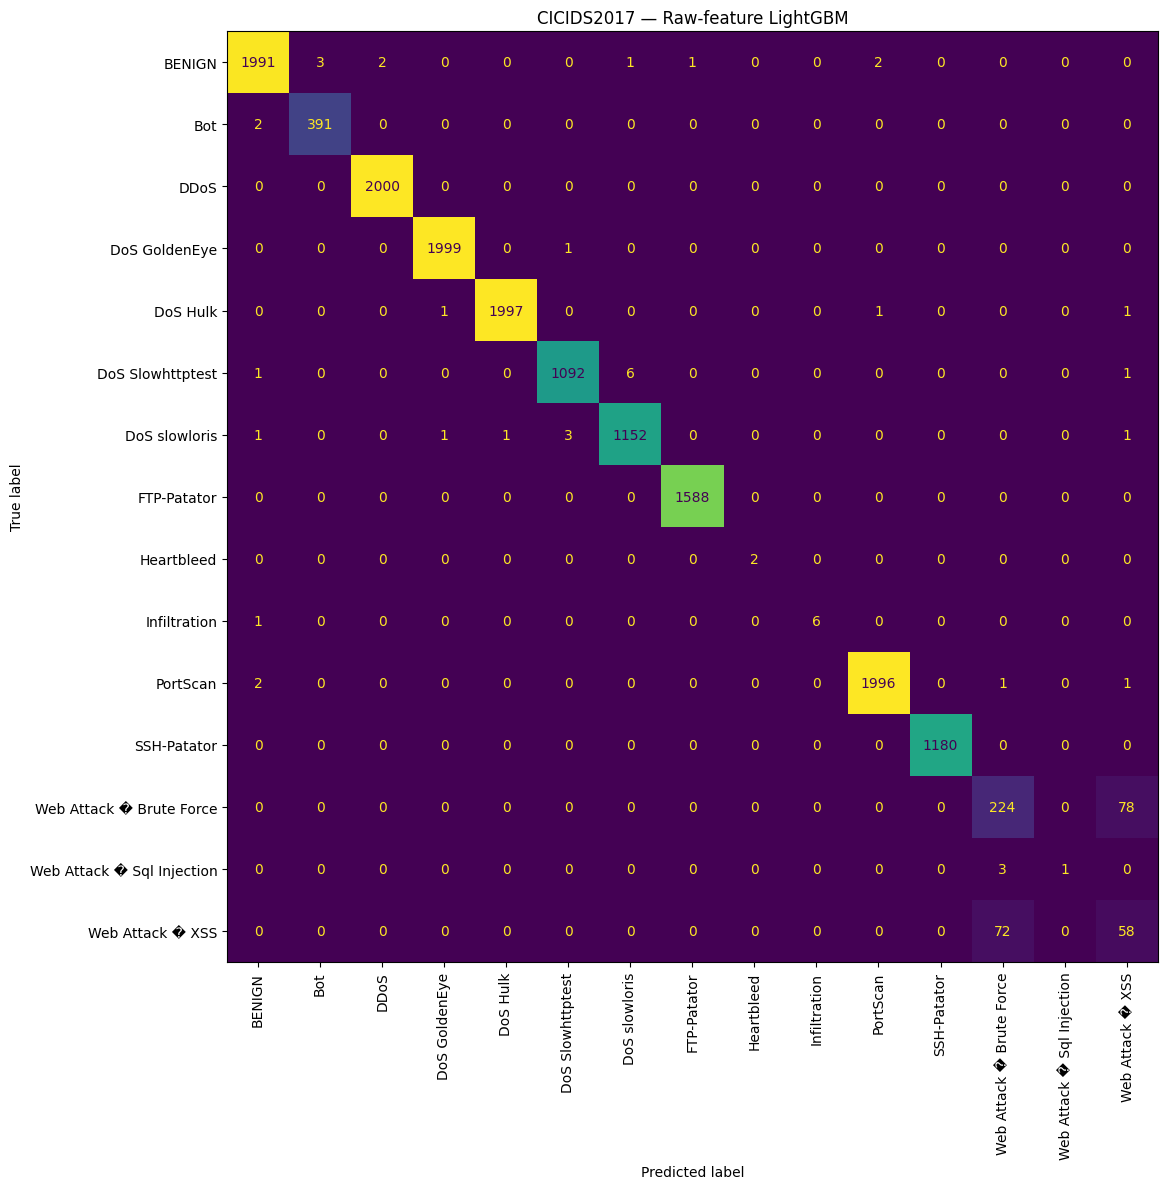


Saved model, predictions, metrics, report, and confusion matrix to:
/content/drive/MyDrive/Intrusion_Detection_Paper_Results


In [13]:

# Install LightGBM if required
%pip -q install lightgbm

import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from lightgbm import LGBMClassifier
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

OUTPUT_DIR = "/content/drive/MyDrive/Intrusion_Detection_Paper_Results"

# Load the exact prepared split from Step 12
data = np.load(
    os.path.join(OUTPUT_DIR, "CICIDS2017_prepared_split.npz"),
    allow_pickle=True
)

X_train = data["X_train"]
X_test = data["X_test"]
y_train = data["y_train"].astype(str)
y_test = data["y_test"].astype(str)
feature_names = data["feature_names"].astype(str)

print("Training shape:", X_train.shape)
print("Test shape:", X_test.shape)

# Calculate balanced class weights from training data only
classes = np.unique(y_train)
weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)
class_weights = dict(zip(classes, weights))

# Provisional configuration; document these settings
model = LGBMClassifier(
    objective="multiclass",
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    colsample_bytree=0.8,
    subsample=0.8,
    subsample_freq=1,
    class_weight=class_weights,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

print("\nTraining baseline LightGBM...")
model.fit(X_train, y_train)

# Held-out predictions
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
macro_f1 = f1_score(
    y_test, y_pred,
    average="macro",
    zero_division=0
)

print("\nBASELINE RESULTS")
print(f"Accuracy: {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Macro F1: {macro_f1:.4f} ({macro_f1 * 100:.2f}%)")

# Save metrics and model configuration
metrics = {
    "dataset": "CICIDS2017 reconstructed pilot",
    "model": "Raw-feature LightGBM",
    "accuracy": float(accuracy),
    "macro_f1": float(macro_f1),
    "train_rows": int(len(y_train)),
    "test_rows": int(len(y_test)),
    "feature_count": int(X_train.shape[1]),
    "seed": 42,
    "n_estimators": 300,
    "learning_rate": 0.05,
    "num_leaves": 31,
    "max_depth": -1,
    "class_weight": "balanced, computed from training labels"
}

with open(
    os.path.join(OUTPUT_DIR, "CICIDS2017_baseline_metrics.json"),
    "w"
) as f:
    json.dump(metrics, f, indent=2)

joblib.dump(
    model,
    os.path.join(OUTPUT_DIR, "CICIDS2017_baseline_lightgbm.joblib")
)

pd.DataFrame({
    "y_true": y_test,
    "y_pred": y_pred
}).to_csv(
    os.path.join(OUTPUT_DIR, "CICIDS2017_baseline_predictions.csv"),
    index=False
)

# Save per-class metrics
report = classification_report(
    y_test,
    y_pred,
    labels=classes,
    output_dict=True,
    zero_division=0
)
pd.DataFrame(report).transpose().to_csv(
    os.path.join(OUTPUT_DIR, "CICIDS2017_baseline_classification_report.csv")
)

# Save confusion matrix and its plot
cm = confusion_matrix(y_test, y_pred, labels=classes)
pd.DataFrame(cm, index=classes, columns=classes).to_csv(
    os.path.join(OUTPUT_DIR, "CICIDS2017_baseline_confusion_matrix.csv")
)

fig, ax = plt.subplots(figsize=(14, 12))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
)
disp.plot(ax=ax, xticks_rotation=90, colorbar=False, values_format="d")
ax.set_title("CICIDS2017 — Raw-feature LightGBM")
fig.tight_layout()
fig.savefig(
    os.path.join(OUTPUT_DIR, "CICIDS2017_baseline_confusion_matrix.png"),
    dpi=200,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

print("\nSaved model, predictions, metrics, report, and confusion matrix to:")
print(OUTPUT_DIR)


Training CNN-BiLSTM encoder...
Epoch 1/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 32s 127ms/step - accuracy: 0.1636 - loss: 2.4590 - val_accuracy: 0.3284 - val_loss: 2.1529
Epoch 2/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 40s 124ms/step - accuracy: 0.3219 - loss: 1.9102 - val_accuracy: 0.3599 - val_loss: 2.0411
Epoch 3/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 27s 121ms/step - accuracy: 0.4374 - loss: 1.6464 - val_accuracy: 0.5570 - val_loss: 1.5470
Epoch 4/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 41s 123ms/step - accuracy: 0.5750 - loss: 1.3601 - val_accuracy: 0.7414 - val_loss: 1.0830
Epoch 5/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 43s 130ms/step - accuracy: 0.7101 - loss: 1.1093 - val_accuracy: 0.6470 - val_loss: 1.4550
Epoch 6/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 40s 125ms/step - accuracy: 0.6742 - loss: 1.1004 - val_accuracy: 0.7277 - val_loss: 0.9169
Epoch 7/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 41s 123ms/step - accuracy: 0.7466 - loss: 0.9299 - val_accuracy: 0.8082 - val_loss: 0.6838
Epoch 8/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 28s 124ms/st

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(



CNN-BiLSTM + LightGBM RESULTS
Accuracy: 0.9842 (98.42%)
Macro-F1: 0.8718 (87.18%)


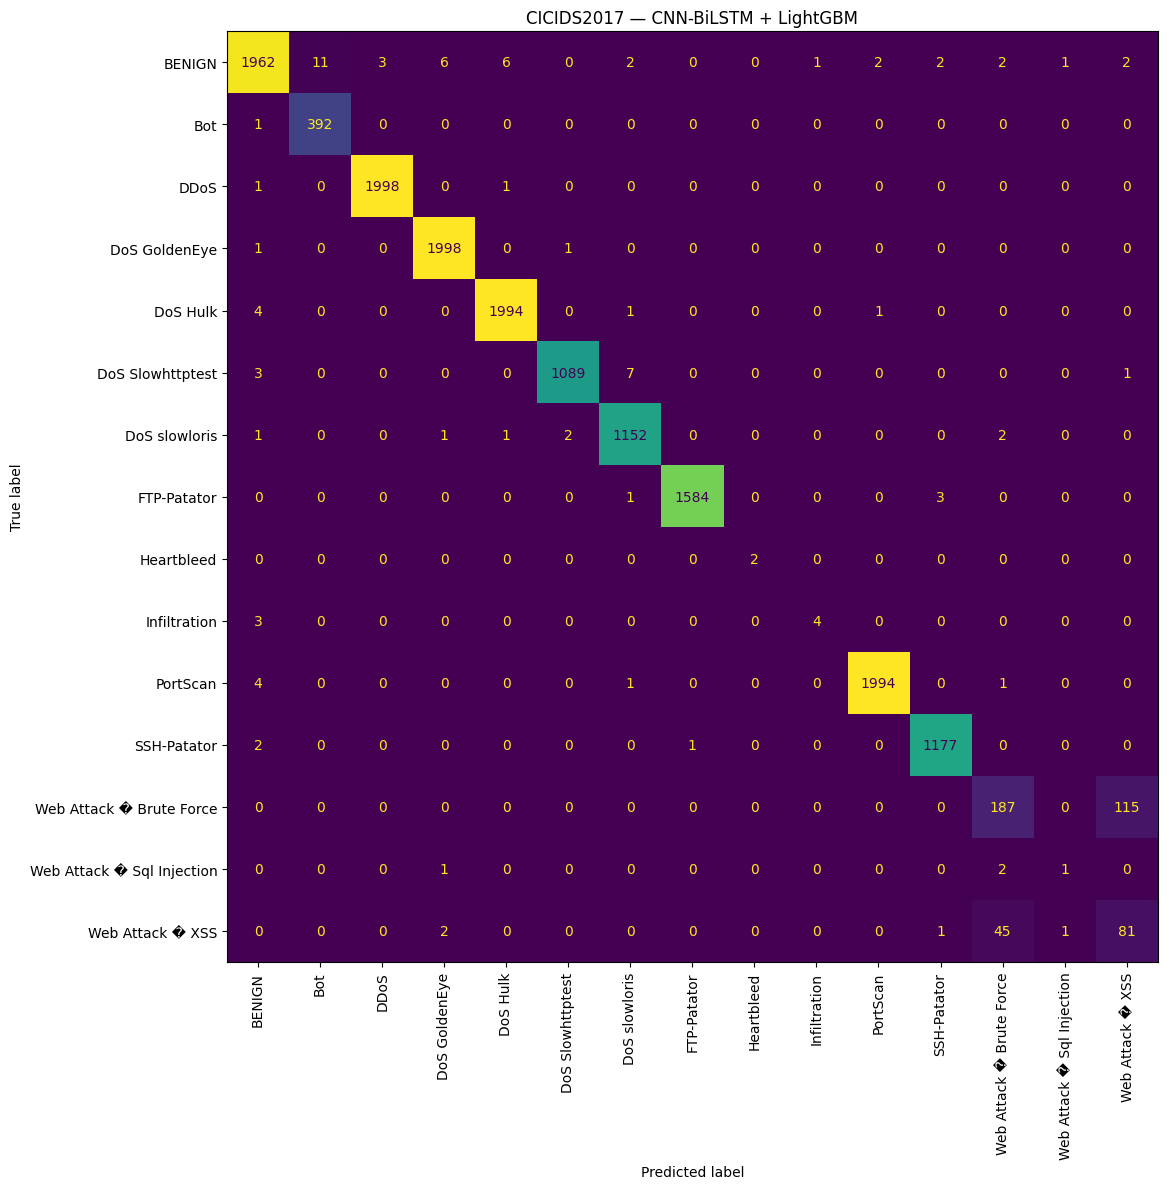


All hybrid outputs saved to: /content/drive/MyDrive/Intrusion_Detection_Paper_Results


In [14]:

%pip -q install tensorflow lightgbm

import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import Model, Input
from tensorflow.keras.layers import (
    Conv1D, Bidirectional, LSTM,
    GlobalAveragePooling1D, Dense
)
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)
from lightgbm import LGBMClassifier

OUTPUT_DIR = "/content/drive/MyDrive/Intrusion_Detection_Paper_Results"
SEED = 42

np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

# Load the exact split used for the baseline
data = np.load(
    os.path.join(OUTPUT_DIR, "CICIDS2017_prepared_split.npz"),
    allow_pickle=True
)

X_train = data["X_train"].astype("float32")
X_test = data["X_test"].astype("float32")
y_train = data["y_train"].astype(str)
y_test = data["y_test"].astype(str)

# Encode class labels for neural-network training
label_encoder = LabelEncoder()
y_train_enc = label_encoder.fit_transform(y_train)

# Ensure the test set uses the same label mapping
y_test_enc = label_encoder.transform(y_test)
num_classes = len(label_encoder.classes_)
num_features = X_train.shape[1]

# CNN-BiLSTM expects sequence-shaped input
X_train_seq = X_train[..., np.newaxis]
X_test_seq = X_test[..., np.newaxis]

# Documented reconstruction architecture
inputs = Input(shape=(num_features, 1), name="traffic_features")

x = Conv1D(
    filters=32, kernel_size=3, padding="same", activation="relu"
)(inputs)

x = Conv1D(
    filters=64, kernel_size=3, padding="same", activation="relu"
)(x)

x = Bidirectional(
    LSTM(32, return_sequences=True)
)(x)

# 64-dimensional learned representation
embedding = GlobalAveragePooling1D(name="embedding_64")(x)
outputs = Dense(num_classes, activation="softmax", name="class_output")(
    embedding
)

encoder_classifier = Model(inputs, outputs)

encoder_classifier.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Balanced weights calculated using training labels only
classes = np.unique(y_train_enc)
weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train_enc
)
nn_class_weights = dict(zip(classes, weights))

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

print("Training CNN-BiLSTM encoder...")
history = encoder_classifier.fit(
    X_train_seq,
    y_train_enc,
    epochs=10,
    batch_size=256,
    validation_split=0.10,
    shuffle=True,
    class_weight=nn_class_weights,
    callbacks=[early_stop],
    verbose=1
)

# Extract 64-dimensional embeddings
embedding_model = Model(
    inputs=encoder_classifier.input,
    outputs=encoder_classifier.get_layer("embedding_64").output
)

Z_train = embedding_model.predict(
    X_train_seq, batch_size=512, verbose=1
)
Z_test = embedding_model.predict(
    X_test_seq, batch_size=512, verbose=1
)

print("Training embeddings:", Z_train.shape)
print("Test embeddings:", Z_test.shape)

# Downstream LightGBM: same settings as baseline
lgbm_weights = dict(zip(
    np.unique(y_train),
    compute_class_weight(
        class_weight="balanced",
        classes=np.unique(y_train),
        y=y_train
    )
))

hybrid_lgbm = LGBMClassifier(
    objective="multiclass",
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    colsample_bytree=0.8,
    subsample=0.8,
    subsample_freq=1,
    class_weight=lgbm_weights,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

print("\nTraining LightGBM on CNN-BiLSTM embeddings...")
hybrid_lgbm.fit(Z_train, y_train)
y_pred = hybrid_lgbm.predict(Z_test)

accuracy = accuracy_score(y_test, y_pred)
macro_f1 = f1_score(
    y_test, y_pred, average="macro", zero_division=0
)

print("\nCNN-BiLSTM + LightGBM RESULTS")
print(f"Accuracy: {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"Macro-F1: {macro_f1:.4f} ({macro_f1*100:.2f}%)")

# Save model artifacts
embedding_model.save(
    os.path.join(OUTPUT_DIR, "CICIDS2017_cnn_bilstm_encoder.keras")
)
joblib.dump(
    hybrid_lgbm,
    os.path.join(OUTPUT_DIR, "CICIDS2017_hybrid_lightgbm.joblib")
)
joblib.dump(
    label_encoder,
    os.path.join(OUTPUT_DIR, "CICIDS2017_label_encoder.joblib")
)

np.savez_compressed(
    os.path.join(OUTPUT_DIR, "CICIDS2017_hybrid_embeddings.npz"),
    Z_train=Z_train,
    Z_test=Z_test
)

pd.DataFrame({
    "y_true": y_test,
    "y_pred": y_pred
}).to_csv(
    os.path.join(OUTPUT_DIR, "CICIDS2017_hybrid_predictions.csv"),
    index=False
)

report = classification_report(
    y_test, y_pred,
    labels=label_encoder.classes_,
    output_dict=True,
    zero_division=0
)
pd.DataFrame(report).transpose().to_csv(
    os.path.join(OUTPUT_DIR, "CICIDS2017_hybrid_classification_report.csv")
)

cm = confusion_matrix(
    y_test, y_pred, labels=label_encoder.classes_
)
pd.DataFrame(
    cm, index=label_encoder.classes_,
    columns=label_encoder.classes_
).to_csv(
    os.path.join(OUTPUT_DIR, "CICIDS2017_hybrid_confusion_matrix.csv")
)

fig, ax = plt.subplots(figsize=(14, 12))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_encoder.classes_
).plot(ax=ax, xticks_rotation=90, colorbar=False, values_format="d")
ax.set_title("CICIDS2017 — CNN-BiLSTM + LightGBM")
fig.tight_layout()
fig.savefig(
    os.path.join(OUTPUT_DIR, "CICIDS2017_hybrid_confusion_matrix.png"),
    dpi=200, bbox_inches="tight"
)
plt.show()
plt.close(fig)

config = {
    "experiment": "Reconstructed CNN-BiLSTM + LightGBM",
    "seed": SEED,
    "input_features": int(num_features),
    "embedding_dimensions": 64,
    "conv_filters": [32, 64],
    "kernel_size": 3,
    "bidirectional_lstm_units": 32,
    "optimizer": "Adam",
    "learning_rate": 0.001,
    "loss": "sparse_categorical_crossentropy",
    "max_epochs": 10,
    "batch_size": 256,
    "validation_split": 0.10,
    "early_stopping_patience": 3,
    "lightgbm_n_estimators": 300,
    "lightgbm_learning_rate": 0.05,
    "accuracy": float(accuracy),
    "macro_f1": float(macro_f1)
}

with open(
    os.path.join(OUTPUT_DIR, "CICIDS2017_hybrid_metrics_config.json"),
    "w"
) as f:
    json.dump(config, f, indent=2)

print("\nAll hybrid outputs saved to:", OUTPUT_DIR)


In [15]:

import os
import json
import numpy as np
import pandas as pd

from sklearn.metrics import accuracy_score, f1_score

OUTPUT_DIR = "/content/drive/MyDrive/Intrusion_Detection_Paper_Results"
N_BOOTSTRAP = 1000
SEED = 42

baseline_path = os.path.join(
    OUTPUT_DIR, "CICIDS2017_baseline_predictions.csv"
)
hybrid_path = os.path.join(
    OUTPUT_DIR, "CICIDS2017_hybrid_predictions.csv"
)

baseline = pd.read_csv(baseline_path)
hybrid = pd.read_csv(hybrid_path)

# Verify paired predictions refer to identical test labels
assert len(baseline) == len(hybrid), "Prediction counts differ."
assert np.array_equal(
    baseline["y_true"].astype(str).to_numpy(),
    hybrid["y_true"].astype(str).to_numpy()
), "The models do not have identical test labels."

y_true = baseline["y_true"].astype(str).to_numpy()
pred_base = baseline["y_pred"].astype(str).to_numpy()
pred_hybrid = hybrid["y_pred"].astype(str).to_numpy()

labels = np.unique(y_true)

def calculate_metrics(y, pred):
    return {
        "Accuracy": accuracy_score(y, pred),
        "Macro-F1": f1_score(
            y, pred, labels=labels,
            average="macro", zero_division=0
        )
    }

base_metrics = calculate_metrics(y_true, pred_base)
hybrid_metrics = calculate_metrics(y_true, pred_hybrid)

comparison = pd.DataFrame([
    {"Model": "Raw-feature LightGBM", **base_metrics},
    {"Model": "CNN-BiLSTM + LightGBM", **hybrid_metrics}
])

comparison["Accuracy (%)"] = comparison["Accuracy"] * 100
comparison["Macro-F1 (%)"] = comparison["Macro-F1"] * 100

comparison.to_csv(
    os.path.join(OUTPUT_DIR, "CICIDS2017_model_comparison.csv"),
    index=False
)

print("MODEL COMPARISON")
print(comparison[
    ["Model", "Accuracy (%)", "Macro-F1 (%)"]
].round(3).to_string(index=False))

# Paired, stratified bootstrap:
# resample within each true class to preserve its test support.
rng = np.random.default_rng(SEED)
class_indices = {
    label: np.flatnonzero(y_true == label)
    for label in labels
}

boot = {
    "Baseline Accuracy": [],
    "Baseline Macro-F1": [],
    "Hybrid Accuracy": [],
    "Hybrid Macro-F1": [],
    "Accuracy Difference (Hybrid - Baseline)": [],
    "Macro-F1 Difference (Hybrid - Baseline)": []
}

for _ in range(N_BOOTSTRAP):
    sampled = np.concatenate([
        rng.choice(idx, size=len(idx), replace=True)
        for idx in class_indices.values()
    ])

    yb = y_true[sampled]
    pb = pred_base[sampled]
    ph = pred_hybrid[sampled]

    mb = calculate_metrics(yb, pb)
    mh = calculate_metrics(yb, ph)

    boot["Baseline Accuracy"].append(mb["Accuracy"])
    boot["Baseline Macro-F1"].append(mb["Macro-F1"])
    boot["Hybrid Accuracy"].append(mh["Accuracy"])
    boot["Hybrid Macro-F1"].append(mh["Macro-F1"])
    boot["Accuracy Difference (Hybrid - Baseline)"].append(
        mh["Accuracy"] - mb["Accuracy"]
    )
    boot["Macro-F1 Difference (Hybrid - Baseline)"].append(
        mh["Macro-F1"] - mb["Macro-F1"]
    )

rows = []
for metric, values in boot.items():
    values = np.asarray(values)
    rows.append({
        "Metric": metric,
        "Estimate": float(np.mean(values)),
        "CI Lower 95%": float(np.percentile(values, 2.5)),
        "CI Upper 95%": float(np.percentile(values, 97.5))
    })

ci_df = pd.DataFrame(rows)
ci_df.to_csv(
    os.path.join(OUTPUT_DIR, "CICIDS2017_bootstrap_confidence_intervals.csv"),
    index=False
)

print("\nBOOTSTRAP 95% CONFIDENCE INTERVALS")
print(ci_df.round(5).to_string(index=False))

print("\nSaved comparison and confidence intervals to:", OUTPUT_DIR)


MODEL COMPARISON
                Model  Accuracy (%)  Macro-F1 (%)
 Raw-feature LightGBM        98.815        89.805
CNN-BiLSTM + LightGBM        98.424        87.177

BOOTSTRAP 95% CONFIDENCE INTERVALS
                                 Metric  Estimate  CI Lower 95%  CI Upper 95%
                      Baseline Accuracy   0.98818       0.98683       0.98948
                      Baseline Macro-F1   0.89523       0.86198       0.92919
                        Hybrid Accuracy   0.98422       0.98248       0.98588
                        Hybrid Macro-F1   0.86985       0.83455       0.90555
Accuracy Difference (Hybrid - Baseline)  -0.00396      -0.00567      -0.00227
Macro-F1 Difference (Hybrid - Baseline)  -0.02538      -0.05084      -0.00552

Saved comparison and confidence intervals to: /content/drive/MyDrive/Intrusion_Detection_Paper_Results


In [16]:

import os
import pandas as pd
from sklearn.metrics import classification_report

OUTPUT_DIR = "/content/drive/MyDrive/Intrusion_Detection_Paper_Results"

baseline = pd.read_csv(
    os.path.join(OUTPUT_DIR, "CICIDS2017_baseline_predictions.csv")
)
hybrid = pd.read_csv(
    os.path.join(OUTPUT_DIR, "CICIDS2017_hybrid_predictions.csv")
)

y_true = baseline["y_true"].astype(str)
pred_base = baseline["y_pred"].astype(str)
pred_hybrid = hybrid["y_pred"].astype(str)

labels = sorted(y_true.unique())

report_base = pd.DataFrame(
    classification_report(
        y_true, pred_base, labels=labels,
        output_dict=True, zero_division=0
    )
).T

report_hybrid = pd.DataFrame(
    classification_report(
        y_true, pred_hybrid, labels=labels,
        output_dict=True, zero_division=0
    )
).T

comparison = report_base[
    ["precision", "recall", "f1-score", "support"]
].add_prefix("Baseline_").join(
    report_hybrid[
        ["precision", "recall", "f1-score", "support"]
    ].add_prefix("Hybrid_")
)

comparison.to_csv(
    os.path.join(OUTPUT_DIR, "CICIDS2017_per_class_comparison.csv")
)

print(comparison.round(4).to_string())
print("\nSaved per-class comparison.")


                            Baseline_precision  Baseline_recall  Baseline_f1-score  Baseline_support  Hybrid_precision  Hybrid_recall  Hybrid_f1-score  Hybrid_support
BENIGN                                  0.9965           0.9955             0.9960         2000.0000            0.9899         0.9810           0.9854       2000.0000
Bot                                     0.9924           0.9949             0.9936          393.0000            0.9727         0.9975           0.9849        393.0000
DDoS                                    0.9990           1.0000             0.9995         2000.0000            0.9985         0.9990           0.9988       2000.0000
DoS GoldenEye                           0.9990           0.9995             0.9993         2000.0000            0.9950         0.9990           0.9970       2000.0000
DoS Hulk                                0.9995           0.9985             0.9990         2000.0000            0.9960         0.9970           0.9965       2000.000

In [17]:

import os

OUTPUT_DIR = "/content/drive/MyDrive/Intrusion_Detection_Paper_Results"

print("RESULT FILES")
for root, dirs, files in os.walk(OUTPUT_DIR):
    for file in sorted(files):
        path = os.path.join(root, file)
        print(f"{file} | {os.path.getsize(path) / 1024:.1f} KB")


RESULT FILES
CICIDS2017_baseline_classification_report.csv | 1.2 KB
CICIDS2017_baseline_confusion_matrix.csv | 0.9 KB
CICIDS2017_baseline_confusion_matrix.png | 230.1 KB
CICIDS2017_baseline_lightgbm.joblib | 13864.4 KB
CICIDS2017_baseline_metrics.json | 0.4 KB
CICIDS2017_baseline_predictions.csv | 329.2 KB
CICIDS2017_bootstrap_confidence_intervals.csv | 0.5 KB
CICIDS2017_cnn_bilstm_encoder.keras | 155.6 KB
CICIDS2017_combined_label_counts.csv | 0.3 KB
CICIDS2017_hybrid_classification_report.csv | 1.2 KB
CICIDS2017_hybrid_confusion_matrix.csv | 0.9 KB
CICIDS2017_hybrid_confusion_matrix.png | 230.5 KB
CICIDS2017_hybrid_embeddings.npz | 17856.6 KB
CICIDS2017_hybrid_lightgbm.joblib | 14817.8 KB
CICIDS2017_hybrid_metrics_config.json | 0.5 KB
CICIDS2017_hybrid_predictions.csv | 328.8 KB
CICIDS2017_label_encoder.joblib | 1.8 KB
CICIDS2017_model_comparison.csv | 0.2 KB
CICIDS2017_per_class_comparison.csv | 2.2 KB
CICIDS2017_pilot_class_counts.csv | 0.3 KB
CICIDS2017_pilot_subset.csv | 27749.2 